# 1. Quickstart: read a page

This notebook reads a page with Carbon-OCR from Python, from start to end. It gets the model set, draws the sample pages the notebooks use, reads one, and goes through everything the engine gives back for it. The later notebooks build on these steps:

| notebook | what |
|---|---|
| **1. Quickstart** | the model set, a page read, what comes back, markdown and HTML, many pages at once |
| 2. The engine's options | every option of `carbon_ocr.Engine`, each tried where it matters, with what it changes |
| 3. Streams and batches | pages as a stream, files decoded by the workers, errors, the batched `Pipeline`, throughput |
| 4. Inside the engine | each step by hand: orientation, detection and its decoder, crops, recognition and CTC, reading order |
| 5. Measuring accuracy | character and word error rates, harder scans, the characters confused, confidence against correctness |
| 6. The command line and the server | `carbon-ocr` and its formats, searchable PDFs, timing tools, `carbon-ocr serve` over HTTP |

**Before you start.** From the repository's root, `pip install ./python` builds the `carbon_ocr` module (it needs CMake and a C++20 compiler), and `pip install -r Examples/requirements.txt` adds Jupyter, matplotlib, Pillow and `huggingface_hub`. [README.md](README.md) has the details.

In [1]:
import difflib
import time

import matplotlib.pyplot as plt
import numpy as np

import carbon_ocr
import helpers
import sample_pages

plt.rcParams["figure.dpi"] = 90
print("carbon_ocr", carbon_ocr.__version__, "| built with CUDA:", carbon_ocr.HAS_CUDA)

carbon_ocr 0.1.0 | built with CUDA: False


## The model set

The engine reads pages with a *set* of Fullerene models, one folder of ONNX files:

| model | what it does |
|---|---|
| `orient` | tells which way up the page is, from a 512 × 512 thumbnail |
| `det` | finds the lines and the pictures, as maps at half the page's scale |
| `rec-latin` | reads each line (Latin script), a class score every 4 pixels, decoded by CTC |
| `order` | puts the lines in reading order, groups them into labelled blocks, finds tables' cells |

The first set, `fullerene-3M`, is on [Hugging Face](https://huggingface.co/CarbonResearchLabs/fullerene-3M). `helpers.model_set()` looks for it in `models/fullerene-3M` at the repository's root, or in the folder the `CARBON_OCR_SET` environment variable names. When it is in neither, it downloads it to `models/fullerene-3M` (about 20 MB).

In [2]:
SET = helpers.model_set()
print("set:", helpers.shown(SET))
for f in sorted(SET.glob("*.onnx")) + sorted(SET.glob("*.bin")):
    print(f"  {f.name:30} {f.stat().st_size / 1e6:5.2f} MB")

set: models/fullerene-3M
  det.fp16.onnx                   0.89 MB
  det.onnx                        1.78 MB
  order.fp16.onnx                 0.99 MB
  order.onnx                      1.96 MB
  orient.fp16.onnx                0.68 MB
  orient.onnx                     1.36 MB
  rec-latin.features.fp16.onnx    2.62 MB
  rec-latin.fp16.onnx             3.03 MB
  rec-latin.onnx                  6.05 MB
  rec-latin.head.bin              0.41 MB


Each model comes as an FP32 file (`<model>.onnx`) and an FP16 one (`<model>.fp16.onnx`). The recognizer's trunk and its last layer also come apart (`rec-latin.features.fp16.onnx` and `rec-latin.head.bin`), for the GPU's fused CTC head. On a CPU the engine runs the FP32 files on ONNX Runtime by default, since this set has no int8 files. Notebook 2 changes that.

## The sample pages

`sample_pages.py` draws the pages these notebooks read, with Pillow and the DejaVu fonts that matplotlib ships. Each page is drawn from known text, so it comes with its truth: every line's text and box. That lets the notebooks measure the engine, not only show it. Your own scans can take their place at any point, since `carbon_ocr.load_image` reads PNG, JPEG, BMP and PNM files.

In [3]:
pages = sample_pages.make_all("data")
for name, path in pages.items():
    t = sample_pages.truth(path)
    print(f"{name:12} {t['width']:5} x {t['height']:<5} {len(t['lines']):4} lines   {helpers.shown(path)}")

letter        1700 x 2200    21 lines   Examples/data/letter.png
columns       1700 x 2200    35 lines   Examples/data/columns.png
table         1700 x 2200    48 lines   Examples/data/table.png
mixed         2550 x 3300    31 lines   Examples/data/mixed.png
newspaper     3400 x 4800   807 lines   Examples/data/newspaper.png
banner        1700 x 2200    14 lines   Examples/data/banner.png
receipt        560 x 3000    55 lines   Examples/data/receipt.png
slide         1920 x 1080     7 lines   Examples/data/slide.png
rotated       2200 x 1700    21 lines   Examples/data/rotated.png
upside-down   1700 x 2200    21 lines   Examples/data/upside-down.png
skewed        1700 x 2200    21 lines   Examples/data/skewed.png
scan          1700 x 2200    21 lines   Examples/data/scan.jpg


uint8 (2200, 1700)


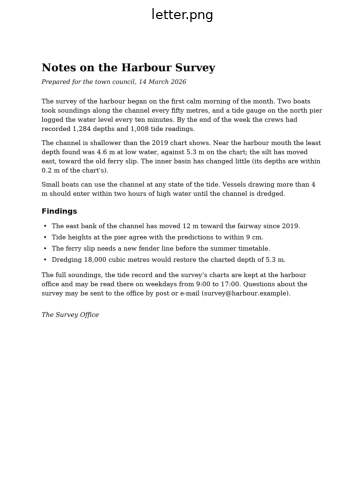

In [4]:
page = carbon_ocr.load_image(pages["letter"])
print(page.dtype, page.shape)  # grayscale, uint8 [height, width], paper 255 and ink 0
helpers.show(page, title="letter.png", width=5);

## Read it

`carbon_ocr.Engine(set)` loads the models once and starts its workers: one per physical core, each pinned to its core. `ocr` takes a list of pages (grayscale uint8 arrays) and reads them in parallel. Making an engine loads every model, so keep one for as long as you have pages to read.

In [5]:
t = time.perf_counter()
engine = carbon_ocr.Engine(SET)
print(f"engine ready in {time.perf_counter() - t:.2f} s, {engine.workers} workers")

engine.ocr([page])  # the first page also warms each worker's caches
t = time.perf_counter()
result = engine.ocr([page])[0]
print(f"read in {(time.perf_counter() - t) * 1000:.0f} ms\n")
print(result["text"])

engine ready in 0.34 s, 10 workers
read in 52 ms

Notes on the Harbour Survey
Prepared for the town council, 14 March 2026
The survey of the harbour began on the first calm morning of the month. Two boats
took soundings along the channel every fifty metres, and a tide gauge on the north pier
logged the water level every ten minutes. By the end of the week the crews had
recorded 1,284 depths and 1,008 tide readings.
The channel is shallower than the 2019 chart shows. Near the harbour mouth the least
depth found was 4.6 m at low water, against 5.3 m on the chart; the silt has moved
east, toward the old ferry slip. The inner basin has changed little (its depths are within
0.2 m of the chart's).
Small boats can use the channel at any state of the tide. Vessels drawing more than 4
m should enter within two hours of high water until the channel is dredged.
Findings
• The east bank of the channel has moved 12 m toward the fairway since 2019.
• Tide heights at the pier agree with the predictio

## What comes back

Each page comes back as a dict:

| key | what |
|---|---|
| `width`, `height` | the page's size in pixels |
| `rotation`, `skew` | the quarter turn (0, 90, 180 or 270) and the angle in degrees the engine undid. The boxes are in the pixels of the page turned upright and levelled |
| `lines` | the lines in reading order, each a dict: `box` (x0, y0, x1, y1), `text`, `confidence` (the mean probability of its characters) and `det_score` (the detector's) |
| `pictures` | the boxes of the pictures the detector found |
| `blocks` | the order model's blocks: `label`, `confidence`, `lines` (indices into `lines`), and for a table its `cells` as (row, column, lines) |
| `order` | `"model"` where the order model's order was used, `"xy-cut"` where the model was unsure and the engine ordered the lines by their geometry |
| `second_pass` | whether the page was detected a second time at twice the scale (tiny text, notebook 2) |
| `ms` | the time of each stage: `orient` (with deskew), `detect`, `decode`, `second_pass`, `recognize`, `total`, and `load` for a file the engine decoded itself |
| `text` | the lines' text in reading order, one line each |

In [6]:
print({k: v for k, v in result.items() if k not in ("lines", "blocks", "pictures", "text", "ms")})
print("ms:", {k: round(v, 1) for k, v in result["ms"].items()}, "\n")
for line in result["lines"][:8]:
    x0, y0, x1, y1 = line["box"]
    print(f"({x0:5.0f} {y0:5.0f} {x1:5.0f} {y1:5.0f})  confidence {line['confidence']:.3f}  "
          f"det {line['det_score']:.2f}  {line['text'][:58]}")

{'width': 1700, 'height': 2200, 'rotation': 0, 'skew': 0.0, 'order': 'model', 'second_pass': False}
ms: {'orient': 8.8, 'detect': 14.6, 'decode': 0.9, 'second_pass': 0.0, 'recognize': 26.8, 'total': 51.9, 'load': 0.0} 

(  156   162  1017   238)  confidence 1.000  det 0.97  Notes on the Harbour Survey
(  161   246   871   293)  confidence 1.000  det 0.98  Prepared for the town council, 14 March 2026
(  161   344  1481   387)  confidence 1.000  det 0.97  The survey of the harbour began on the first calm morning 
(  161   390  1537   433)  confidence 1.000  det 0.92  took soundings along the channel every fifty metres, and a
(  157   434  1416   477)  confidence 1.000  det 0.98  logged the water level every ten minutes. By the end of th
(  157   480   913   522)  confidence 1.000  det 0.99  recorded 1,284 depths and 1,008 tide readings.
(  161   549  1532   592)  confidence 1.000  det 0.92  The channel is shallower than the 2019 chart shows. Near t
(  161   593  1468   636)  confidence 1

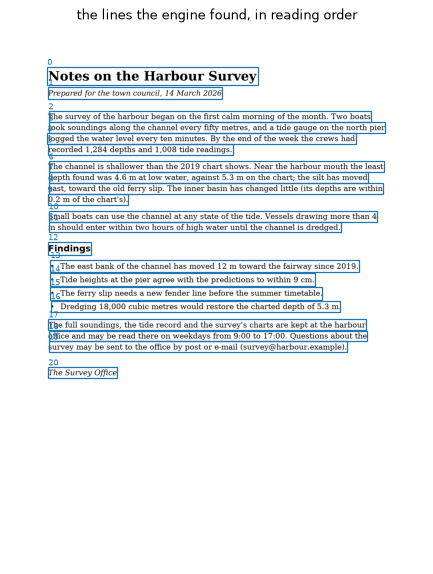

In [7]:
helpers.show(page, result["lines"], title="the lines the engine found, in reading order", width=6, label=True);

In [8]:
for block in result["blocks"]:
    first = result["lines"][block["lines"][0]]["text"]
    print(f"{block['label']:15} confidence {block['confidence']:.2f}  {len(block['lines']):2} lines   {first[:50]}")

Section-Header  confidence 1.00   1 lines   Notes on the Harbour Survey
Text            confidence 0.91   1 lines   Prepared for the town council, 14 March 2026
Text            confidence 1.00   4 lines   The survey of the harbour began on the first calm 
Text            confidence 1.00   4 lines   The channel is shallower than the 2019 chart shows
Text            confidence 1.00   2 lines   Small boats can use the channel at any state of th
Section-Header  confidence 1.00   1 lines   Findings
List-Group      confidence 1.00   1 lines   • The east bank of the channel has moved 12 m towa
List-Group      confidence 1.00   1 lines   • Tide heights at the pier agree with the predicti
List-Group      confidence 1.00   1 lines   • The ferry slip needs a new fender line before th
List-Group      confidence 1.00   1 lines   • Dredging 18,000 cubic metres would restore the c
Text            confidence 1.00   3 lines   The full soundings, the tide record and the survey
Text            confidence

The order model labels each block. The title and the heading are `Section-Header` blocks, the date line and the paragraphs `Text`, and each bulleted finding a `List-Group`. Its other labels are in `carbon_ocr.BLOCK_LABELS`. Tables come with their cells (notebook 2), and running headers and footers have labels of their own, so the writers can leave them out.

In [9]:
print(carbon_ocr.BLOCK_LABELS)

['Text', 'Section-Header', 'Page-Header', 'Page-Footer', 'List-Group', 'Table', 'Caption', 'Footnote', 'Table-Of-Contents', 'Form', 'Picture', 'Formula', 'Other']


## Markdown and HTML

`ocr(pages, markdown=True, html=True)` also writes each page as `carbon-ocr --format markdown` and `--format html` write it, from its blocks: headings, paragraphs (a block's lines joined into one), lists and tables. The writing runs in C++, outside Python's lock.

In [10]:
result = engine.ocr([page], markdown=True, html=True)[0]
print(result["markdown"])

## Notes on the Harbour Survey

Prepared for the town council, 14 March 2026

The survey of the harbour began on the first calm morning of the month. Two boats took soundings along the channel every fifty metres, and a tide gauge on the north pier logged the water level every ten minutes. By the end of the week the crews had recorded 1,284 depths and 1,008 tide readings.

The channel is shallower than the 2019 chart shows. Near the harbour mouth the least depth found was 4.6 m at low water, against 5.3 m on the chart; the silt has moved east, toward the old ferry slip. The inner basin has changed little (its depths are within 0.2 m of the chart's).

Small boats can use the channel at any state of the tide. Vessels drawing more than 4 m should enter within two hours of high water until the channel is dredged.

## Findings

- The east bank of the channel has moved 12 m toward the fairway since 2019.

- Tide heights at the pier agree with the predictions to within 9 cm.

- The ferry slip 

In [11]:
from IPython.display import HTML, display

print(result["html"][:700], "...")
display(HTML(result["html"]))

<h2>Notes on the Harbour Survey</h2>
<p>Prepared for the town council, 14 March 2026</p>
<p>The survey of the harbour began on the first calm morning of the month. Two boats took soundings along the channel every fifty metres, and a tide gauge on the north pier logged the water level every ten minutes. By the end of the week the crews had recorded 1,284 depths and 1,008 tide readings.</p>
<p>The channel is shallower than the 2019 chart shows. Near the harbour mouth the least depth found was 4.6 m at low water, against 5.3 m on the chart; the silt has moved east, toward the old ferry slip. The inner basin has changed little (its depths are within 0.2 m of the chart's).</p>
<p>Small boats can  ...


## How close is it?

The page was drawn from known text, so measuring the engine on it takes one call. `carbon_ocr.text_errors(truths, predicted)` gives four numbers for each pair: the edit distance in characters and the truth's length in characters, then the same in words. Their ratios are the character and word error rates (CER and WER). Notebook 5 measures the engine this way on harder pages.

In [12]:
truth = sample_pages.truth_text(pages["letter"])
chars_wrong, chars, words_wrong, words = carbon_ocr.text_errors([truth], [result["text"]])[0]
print(f"CER {chars_wrong / chars:.2%} ({chars_wrong} of {chars} characters), "
      f"WER {words_wrong / words:.2%} ({words_wrong} of {words} words)")
for d in difflib.ndiff(truth.splitlines(), result["text"].splitlines()):
    if d[0] in "-+?":
        print(d)

CER 0.00% (0 of 1372 characters), WER 0.00% (0 of 255 words)


## Many pages, any way up

`ocr` takes many pages at once and spreads them over the workers. The engine finds each page's orientation and turns it upright by quarter turns, then levels whatever skew is left, up to 5°. `rotated`, `upside-down` and `skewed` are the letter turned by 90°, by 180° and by 2.5°. `scan.jpg` is the letter as a poor scan: tinted paper, faded ink, blur, noise, a 0.6° skew and hard JPEG compression.

5 pages in 239 ms

letter       rotation   0  skew  0.00°  lines 21  CER 0.00%
rotated      rotation  90  skew  0.00°  lines 21  CER 0.00%
upside-down  rotation 180  skew  0.00°  lines 21  CER 0.00%
skewed       rotation   0  skew  2.50°  lines 21  CER 0.00%
scan         rotation   0  skew  0.60°  lines 21  CER 0.00%


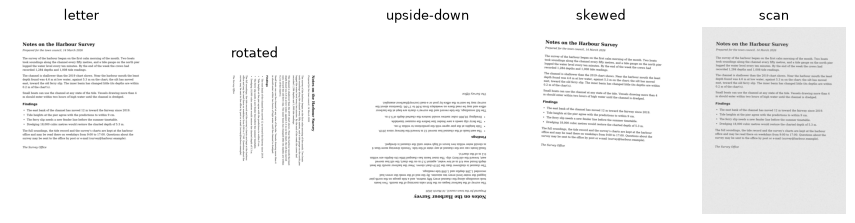

In [13]:
names = ["letter", "rotated", "upside-down", "skewed", "scan"]
images = [carbon_ocr.load_image(pages[n]) for n in names]
t = time.perf_counter()
results = engine.ocr(images)
print(f"{len(images)} pages in {(time.perf_counter() - t) * 1000:.0f} ms\n")
for name, r in zip(names, results):
    e = carbon_ocr.text_errors([truth], [r["text"]])[0]
    print(f"{name:12} rotation {r['rotation']:3}  skew {r['skew']:5.2f}°  lines {len(r['lines']):2}  CER {e[0] / e[1]:.2%}")

fig, axes = plt.subplots(1, len(names), figsize=(12, 3.4))
for ax, name, image in zip(axes, names, images):
    helpers.show(image, ax=ax, title=name)

Every page reads the same as the letter itself. The boxes of a turned page are in the pixels of the page as the engine turned it upright, so they line up with the letter's.

## Next

- [2. The engine's options](02-engine-options.ipynb): what each option of `Engine` changes, measured on these pages.
- [3. Streams and batches](03-streams-and-batches.ipynb): reading many pages, as a list or a stream, with the CPU engine or the batched pipeline.
- [4. Inside the engine](04-inside-the-engine.ipynb): every step of a page's path, by hand.
- [5. Measuring accuracy](05-measuring-accuracy.ipynb): error rates, harder scans, and how far to trust a line's confidence.
- [6. The command line and the server](06-command-line-and-server.ipynb): `carbon-ocr`, its formats and its HTTP server.